# Practice 4 — PageRank,  power laws and ego networks

This practice continues the analysis developed in **`Pract_3_Twitter_Directed_Networks`**.

We use the same directed graph `G` and the same politician information used in Practice 3: node names, usernames and party affiliation.

The main objectives are to:

- compute and interpret **PageRank**;
- compare PageRank with **betweenness**, **strength**, **in-degree**, and **out-degree**;
- identify the politicians with the highest and lowest PageRank;
- study whether the main node measures have a **heavy-tailed / power-law** distribution;
- create and interpret an **ego network**.

##  Use the graph and politician information from Practice 3

We represent the Twitter network introduced in Practice 3, that was represented as a directed graph `G`.

Each node represents a politician, while a directed edge represents a Twitter relation between two politicians.

We also use the same politician metadata as in Practice 3:

- `username`
- `first`
- `last`
- `party_name`


In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from matplotlib import cm
from matplotlib.colors import Normalize
from IPython.display import display, Markdown

from pathlib import Path

In [6]:

DATA_DIR = Path("congress_network")

edge_candidates = list(DATA_DIR.rglob("*.edgelist"))

edge_path = edge_candidates[0]
print("Using:", edge_path)

G = nx.read_edgelist(
    edge_path,
    create_using=nx.DiGraph(),
    nodetype=int,
    data=True
)

print(G)
print("Directed:", G.is_directed())
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

# Inspect some edges and their attributes
list(G.edges(data=True))[:5]

Using: congress_network\congress_network\congress.edgelist
DiGraph with 475 nodes and 13289 edges
Directed: True
Number of nodes: 475
Number of edges: 13289


[(0, 4, {'weight': 0.002105263157894737}),
 (0, 12, {'weight': 0.002105263157894737}),
 (0, 18, {'weight': 0.002105263157894737}),
 (0, 25, {'weight': 0.004210526315789474}),
 (0, 30, {'weight': 0.002105263157894737})]

## 1. PageRank

### 1.1 PageRank algorithm

PageRank is a recursive measure of node importance. The main idea is:

> A node is important if it receives links from other important nodes.

For a node $u$, PageRank can be written as

$$
PR(u)=\frac{1-\alpha}{N}
+\alpha
\sum_{vrightarrow u}
frac{w_{vu}PR(v)}
{sum_k w_{vk}}
$$

where:

- $N$ is the total number of nodes;
- $alpha$ is the damping factor, usually $alpha=0.85$;
- $vrightarrow u$ represents a directed edge from $v$ to $u$;
- $w_{vu}$ is the weight of the edge from $v$ to $u$;
- $sum_k w_{vk}$ is the total outgoing weight of node $v$.

The first term, $frac{1-alpha}{N}$, represents the probability of jumping randomly to any node.

The second term propagates importance through incoming links.

Therefore, PageRank differs from simple in-degree: **an incoming link contributes more when it comes from a node that itself has high PageRank**.

count    475.0000
mean       0.0021
std        0.0019
min        0.0003
25%        0.0009
50%        0.0015
75%        0.0025
max        0.0167
Name: pagerank, dtype: float64

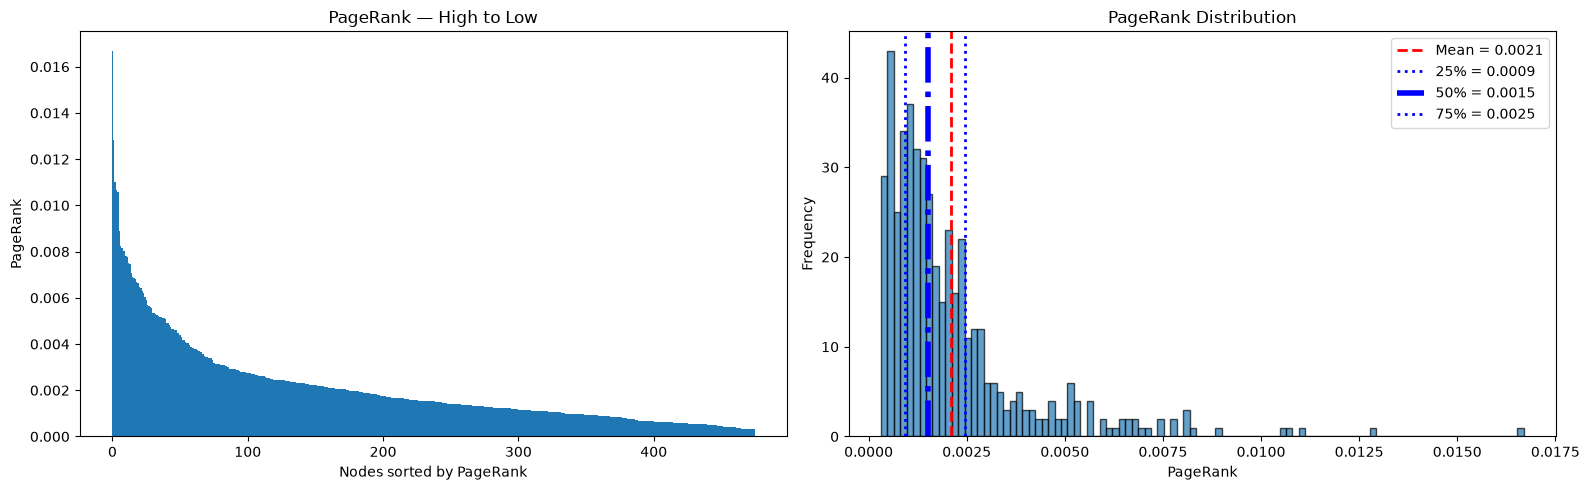

In [9]:
# -------------------------------------------------------
# Compute PageRank
# -------------------------------------------------------

pagerank = nx.pagerank(G, alpha=0.85, weight="weight")
nx.set_node_attributes(G, pagerank, "pagerank")

pr = pd.Series(pagerank, name="pagerank")
display(pr.describe().round(4))

# -------------------------------------------------------
# PageRank distribution
# -------------------------------------------------------

pr_sorted = pr.sort_values(ascending=False)

mean_pr = pr.mean()
median_pr = pr.median()
q25, q50, q75 = pr.quantile([0.25, 0.50, 0.75])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# PageRank sorted from high to low
axes[0].bar(range(len(pr_sorted)), pr_sorted.values, width=1)
axes[0].set_xlabel("Nodes sorted by PageRank")
axes[0].set_ylabel("PageRank")
axes[0].set_title("PageRank — High to Low")

# Histogram
axes[1].hist(pr, bins=100, edgecolor="black", alpha=0.7)
axes[1].axvline(mean_pr,color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pr:.4f}")
axes[1].axvline(q25, color="blue", linestyle=":", linewidth=2, label=f"25% = {q25:.4f}")
axes[1].axvline(q50, color="blue", linestyle="-.", linewidth=4, label=f"50% = {q50:.4f}")
axes[1].axvline(q75, color="blue", linestyle=":", linewidth=2, label=f"75% = {q75:.4f}")
axes[1].set_xlabel("PageRank")
axes[1].set_ylabel("Frequency")
axes[1].set_title("PageRank Distribution")
axes[1].legend()

plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 1</b></font>


1. Explain briefly in your words the idea that underlies the page rank algorithm.
2. Try with different values of alfa, and see how the distribution of pagerank  and histogram changes. What does it mean to make an alfa small?
3. Be aware that in the histogram, the mean and the 50% percentile are different.
4. Inspired in the figures below, explain the meaning of the alfa parameter.

<div style="display: flex; justify-content: center; align-items: center; gap: 20px;">
    <img src="BowTie2.jpeg" width="15%">
    <img src="BowTieModelWeb.png" width="15%">
</div>

## <font color="green"><b>Exercise 1</b></font>


1. La idea del algoritmo de page rank és que la importancia de un nodo recae en la cantidad de nodos y la importancia de los nodos que le apuntan, de manera general y simplista, si a un nodo no le apunta apenas nadie es poco importante, en cambio si le apuntan muchos otros nodos y además estos tambíen son importante, entonces este nodo es muy importante.
2. Si disminuimos el valor de alfa damos más valor a la aleatoriedad de los saltos entre nodos, por tanto la importáncia de cada nodo es muy similar a la del resto, ya que estamos diciendo que la impotáncia depende de saltos alteaorios. En cambio para valores más grande damos importáncia a las conexiones entrantes de los nodos, a lo que hemos mencionado en el apartado anterior.
3. Esto es común, como hemos visto en la teoría, para redes de escala libre el valor más reperesentativo en el percentil 50%, ya que este nos permite ver donde se encuentra la mitad de las muestras, en cambio la medía se ve adulterada por los outliers sin limitación.
4. Alpha es el dampling factor, y controla e balance entre los links existentes en la red y saltar aleatoriamente a un nodo concreto. Un valor más alto de alfa asigna mayor importancia a los links de la red, en cambio un valor más bajo asigna mayor importancia a los saltos aleatorios. En la segunda imagen vemos una representación de una red direccionada, donde podemos destacar que los distintos nodos tiene distintas posibilidades de llegar a otro nodo igual que en la primera.

### 1.2 Visualize PageRank

The graph is plotted using a spring layout.

The node colors encode two variables:

- **Republicans:** blue;
- **Democrats:** red;
- darker colors correspond to larger PageRank values.

####  Below is the table that relates node number with identity and affiliation

In [10]:
party_names = pd.read_pickle("party_names.pkl")
party_names

,node,username,twitter_lower,first,last,party,state,chamber,district,Official,party_name
0,0,SenatorBaldwin,senatorbaldwin,tammy,baldwin,D,WI,Senate,NaN,1.0,Democrat
1,1,SenJohnBarrasso,senjohnbarrasso,john,barrasso,R,WY,Senate,NaN,1.0,Republican
2,2,SenatorBennet,senatorbennet,michael,bennet,D,CO,Senate,NaN,1.0,Democrat
3,3,MarshaBlackburn,marshablackburn,marsha,blackburn,R,TN,House,7,0.0,Republican
4,4,SenBlumenthal,senblumenthal,richard,blumenthal,D,CT,Senate,NaN,1.0,Democrat
...,...,...,...,...,...,...,...,...,...,...,...
470,470,RepJoeWilson,repjoewilson,joe,wilson,R,SC,House,2,1.0,Republican
471,471,RobWittman,robwittman,robert,wittman,R,VA,House,1,0.0,Republican
472,472,rep_stevewomack,rep_stevewomack,steve,womack,R,AR,House,3,1.0,Republican
473,473,RepJohnYarmuth,repjohnyarmuth,john,yarmuth,D,KY,House,3,1.0,Democrat


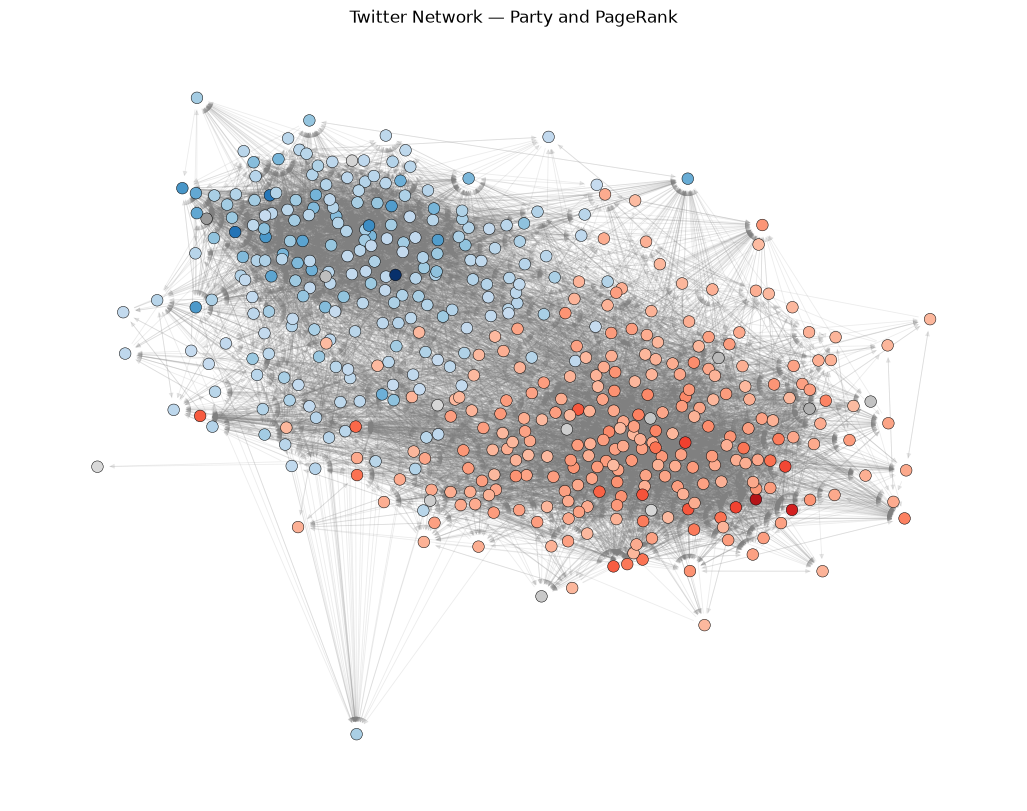

In [11]:
# -------------------------------------------------------
# PageRank visualization
# -------------------------------------------------------

party_names = pd.read_pickle("party_names.pkl").set_index("node")

pos = nx.spring_layout(G, seed=42)
pr_values = np.array([pagerank[n] for n in G.nodes()])
norm = Normalize(vmin=pr_values.min(), vmax=pr_values.max())

node_colors = []

for n in G.nodes():
    party = party_names.loc[n, "party_name"]
    intensity = 0.25 + 0.75 * norm(pagerank[n])

    if party == "Democrat":
        node_colors.append(cm.Reds(intensity))
    elif party == "Republican":
        node_colors.append(cm.Blues(intensity))
    else:
        node_colors.append(cm.Greys(intensity))

plt.figure(figsize=(13, 10))

nx.draw_networkx_edges(G, pos, edge_color="gray", alpha=0.15, width=0.6, arrows=True, arrowsize=7)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=70, edgecolors="black", linewidths=0.35)

plt.title("Twitter Network — Party and PageRank")
plt.axis("off")
plt.show()

## Higher Pagerank nodes vs lower pagerank nodes.

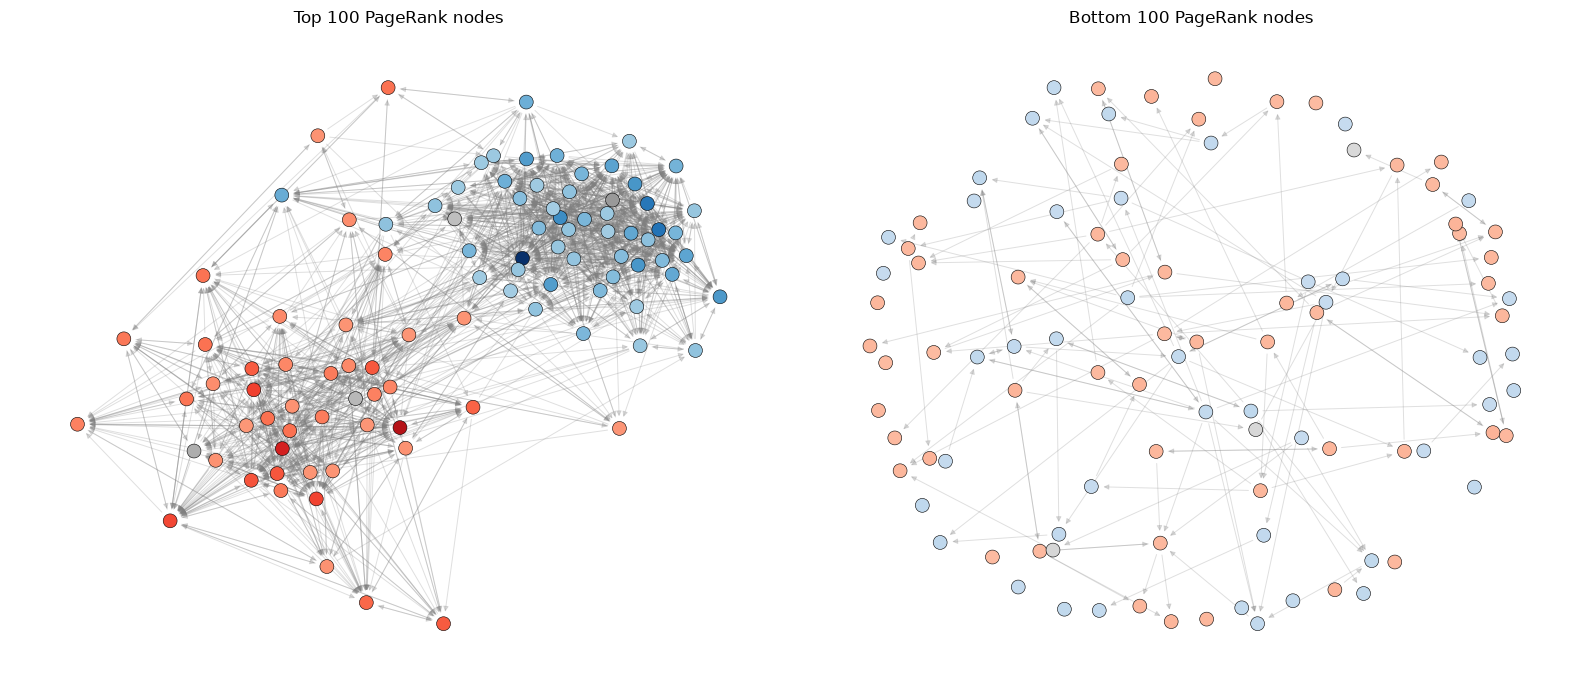

In [12]:
# -------------------------------------------------------
# Highest and lowest PageRank subnetworks
# -------------------------------------------------------

N = 100
party_names = pd.read_pickle("party_names.pkl").set_index("node")

high_nodes = sorted(pagerank, key=pagerank.get, reverse=True)[:N]
low_nodes = sorted(pagerank, key=pagerank.get)[:N]

G_high = G.subgraph(high_nodes)
G_low = G.subgraph(low_nodes)

norm = Normalize(vmin=min(pagerank.values()), vmax=max(pagerank.values()))

def get_colors(nodes):
    colors = []
    for n in nodes:
        party = party_names.loc[n, "party_name"]
        intensity = 0.25 + 0.75 * norm(pagerank[n])

        if party == "Democrat":
            colors.append(cm.Reds(intensity))
        elif party == "Republican":
            colors.append(cm.Blues(intensity))
        else:
            colors.append(cm.Greys(intensity))
    return colors

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, H, title in zip(axes, [G_high, G_low], [f"Top {N} PageRank nodes", f"Bottom {N} PageRank nodes"]):
    pos = nx.spring_layout(H, seed=42)
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color="gray", alpha=0.25, width=0.7, arrows=True, arrowsize=8)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_color=get_colors(H.nodes()), node_size=100, edgecolors="black", linewidths=0.4)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 2</b></font>

Interpret the PageRank visualization.

1. Identify in the first graph the location of the elements with the highest page rank. Explain the meaning that the two highest should be of different parties, and the their location in the network.
2. Which is a first glance difference between the left (high pagerank nodes) and the right (low page rank nodes). Write a parragraph explaining the difference in connectivity, density, clustering, number of triangles. Is the low pagerank graph less partisan?
3. Is a high PageRank necessarily equivalent to having many direct connections?

## <font color="green"><b>Exercise 2</b></font>

1. The elements with highest pagerank are the dark blue and the dark red, both closer to the other party than most of the other nodes. The two highest should be of different parties beacuse every party must have a lider, and this lider probably is the person with most inner strength of the party, it would be extrange to have 2 persons with incredible inner strength in the same party and more than the other party. Also their location in the network for both is approximaely in the middle of their party, beacuse they are probably the most important, but also closer to the other party, beacuse as seen in practices before, is really important to me a betweeness node.
2. The principla difference is the way the nodes are distributed, as we can see there are much less conectivities, most of the nodes have a maximum of 2 inner connectivities, there are no trinagles or clusters, is seams that the nodes are almos randomly distributed, ant the majority are in the outter zone, meaning they have no connections, they have a low pagerank value beacuse they don't have connectivities, the density of the subnetwork they form is really poor. Yes, the low pagerank is less partisian, in fact is almos 0, beacuse there are no clusters for the parties.
3. No necesariamente aunque ayuda, concretamente es importante tener muchas inner connection, pero teniendo muchas simplemente no podemos afirmar que vayas a tener un mayor valor, tambien es impotante conocer la importancia de estos nodos que te apuntas y a cuantos nodos más apuntan estos. Ya que puedes tener 2 inner connection de 2 nodos muy importantes que solo te apuntan a ti y esto te situará con un buen valor, o puedes tener 12 inner conncetions de 12 nodos poco importantes que aputnan a muchisimos nodos de la red pero nadie los apunta, y esto no te dará un gran valor de pagerank

## 2. Betweenness, strength, in-degree and out-degree

We now compute several additional node-level measures.

### 2.1 In-degree and out-degree

For node $i$, the **in-degree** is $k_i^{in}=sum_j A_{ji}$ and the **out-degree** is $k_i^{out}=sum_j A_{ij}$.

- **in-degree** counts incoming edges;
- **out-degree** counts outgoing edges.

### 2.2 Strength

If the graph is weighted, degree can be generalized to **strength**.

Incoming strength is $s_i^{in}=sum_j w_{ji}$, while outgoing strength is $s_i^{out}=sum_j w_{ij}$.

The total strength is $s_i=s_i^{in}+s_i^{out}$.

### 2.3 Betweenness centrality

Betweenness centrality measures how frequently a node belongs to shortest paths between other nodes: $C_B(v)=sum_{sneq vneq t}frac{sigma_{st}(v)}{sigma_{st}}$, where:

- $sigma_{st}$ is the number of shortest paths from $s$ to $t$;
- $sigma_{st}(v)$ is the number of those paths passing through $v$.

A politician with high betweenness may act as a **broker** or bridge between different parts of the network.

,username,first,last,party_name,pagerank,betweenness,in_degree,out_degree,in_strength,out_strength,strength,degree
node,,,,,,,,,,,,
322,GOPLeader,kevin,mccarthy,Republican,0.0167,0.0730,127,157,1.6483,0.8272,2.4755,284
147,RepCasten,sean,casten,Democrat,0.0128,0.0106,97,51,0.8142,0.1146,0.9288,148
389,RepChipRoy,chip,roy,Republican,0.0110,0.0118,84,55,0.9519,0.1660,1.1178,139
269,RepMikeJohnson,mike,johnson,Republican,0.0107,0.0112,106,57,0.9654,0.2303,1.1957,163
215,RepChuyGarcia,Chuy,Garcia,Democrat,0.0106,0.0067,76,45,0.6100,0.1511,0.7611,121
208,RepFranklin,scott,franklin,Republican,0.0089,0.0169,121,61,0.8302,0.5183,1.3486,182
92,RepAdams,alma,adams,Democrat,0.0082,0.0125,94,44,0.6168,0.1611,0.7779,138
246,CongressmanHice,jody,hice,Republican,0.0082,0.0022,59,29,0.5370,0.1693,0.7062,88
303,RepAndyLevin,andy,levin,Democrat,0.0080,0.0155,97,66,0.6327,0.1207,0.7534,163


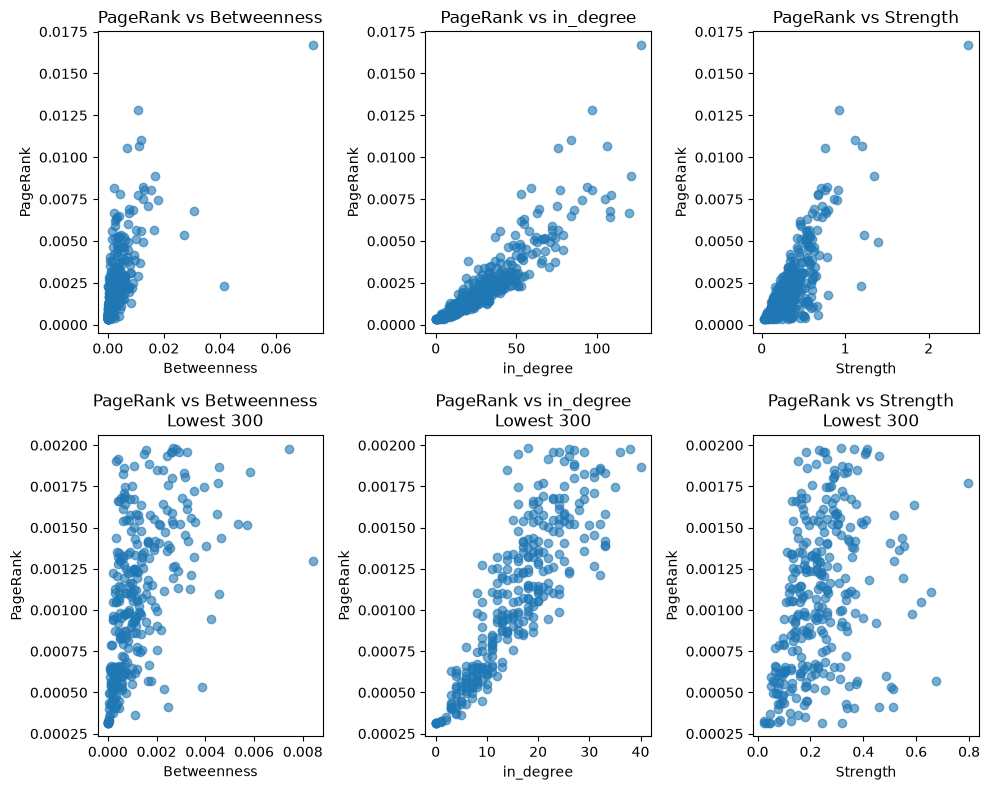

In [13]:
betweenness = nx.betweenness_centrality(G, normalized=True, weight=None)
in_degree, out_degree = dict(G.in_degree()), dict(G.out_degree())
in_strength, out_strength = dict(G.in_degree(weight="weight")), dict(G.out_degree(weight="weight"))
strength = {n: in_strength[n] + out_strength[n] for n in G.nodes()}

metrics = party_names[["username", "first", "last", "party_name"]].join(
    pd.DataFrame({
        "pagerank": pagerank,
        "betweenness": betweenness,
        "in_degree": in_degree,
        "out_degree": out_degree,
        "in_strength": in_strength,
        "out_strength": out_strength,
        "strength": strength
    }),
    how="inner"
)

metrics["degree"] = metrics["in_degree"] + metrics["out_degree"]
metrics = metrics.sort_values("pagerank", ascending=False)

display(metrics.head(15).round(4))
fig, axes = plt.subplots(2, 3, figsize=(10, 8))

# -------------------------------------------------------
# Row 1: All nodes
# -------------------------------------------------------

for ax, x, label in zip(axes[0], ["betweenness", "in_degree", "strength"], ["Betweenness", "in_degree", "Strength"]):
    ax.scatter(metrics[x], metrics["pagerank"], alpha=0.6)
    ax.set_xlabel(label)
    ax.set_ylabel("PageRank")
    ax.set_title(f"PageRank vs {label}")

# -------------------------------------------------------
# Row 2: 300 nodes with lowest PageRank
# -------------------------------------------------------

N = 300
metrics_low = metrics.nsmallest(N, "pagerank")

for ax, x, label in zip(axes[1], ["betweenness", "in_degree", "strength"], ["Betweenness", "in_degree", "Strength"]):
    ax.scatter(metrics_low[x], metrics_low["pagerank"], alpha=0.6)
    ax.set_xlabel(label)
    ax.set_ylabel("PageRank")
    ax.set_title(f"PageRank vs {label}  n  Lowest {N}")

plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 3</b></font>


1. Explain from the underlying idea of page rank, why it is highly correlated to degree, but less to strength or betweeness.
2. Note that McCarthy is the highest ranked by pagerank, but Pelosi does not appear in the first 15  places. 
- Google: who is sean casten and why he is important
3. Pagerank reflects a more structural importance, argue briefly why?

## <font color="green"><b>Exercise 3</b></font>


1. La idea de Pagerank es que la importancia de un nodo recae es sus inner connections, por tanto recae princiaplmente en el inner degree, es cierto que tambien se valora la improtancia de los los nodos que apuntan al nodo que se valua, pero es más probable que un nodo con un valor alto de inner degree tenga mayor pagerank, cabe destacar que con la strength tambíen hay cierta relación, ya que al final indica la fuerza de una conexión, pero puedes existir mucha fuerza de conexion entre 2 nodos pero que estos solo tengan una inner connection, por tanto no es muy importante, y finalmente el betweeness apenas tiene relación, ya que estar en una posicón que connecta muchos nodos no hace necesariamente que muchos nodos se conecten a tí o que seas un nodo importante para el pagerank.
2. McCarthy es un caso excepcional, tiene muchas conexiones, además de tener conexiones fuertes, estar e una ubicación céntrica entre los dos partidos y tener reprocity, es un nodo excepcional y por ello tambíen tiene un alto valor en el pagerank. En cambio Pelosi en la práctica anterior destacaba debido a su fuerza y su posición, pero los nodos que le apuntan no eran tantos ni tan importantes, el tema es que se encontraba cerca del partido republicando y podía hacer de puente, otrogando así importancía y teniendo un betweeness alto, pero el page rank no valora esto, por ello pierde tantas posiciones. 
3. Sí que representa importancia estructural, ya que no valora solo el numero de conexiones entrantes a un nodo, sino que que tambíen valora la importancia de los nodos conectados a este. Por tanto la importáncia de un nodo depende de las conexiones del resto de nodos en la red. El punto a tener en cuenta es que muestra una información estructural muy distinta por ejemplo a la que proporciona el betweeness, el cual también proprociona información relevante sobre la estructura.

## 3. Pearson correlation of PageRank with the other node measures



Pearson correlation to pagerank:


pagerank       1.000
betweenness    0.662
strength       0.796
in_degree      0.903
out_degree     0.466
Name: pagerank, dtype: float64

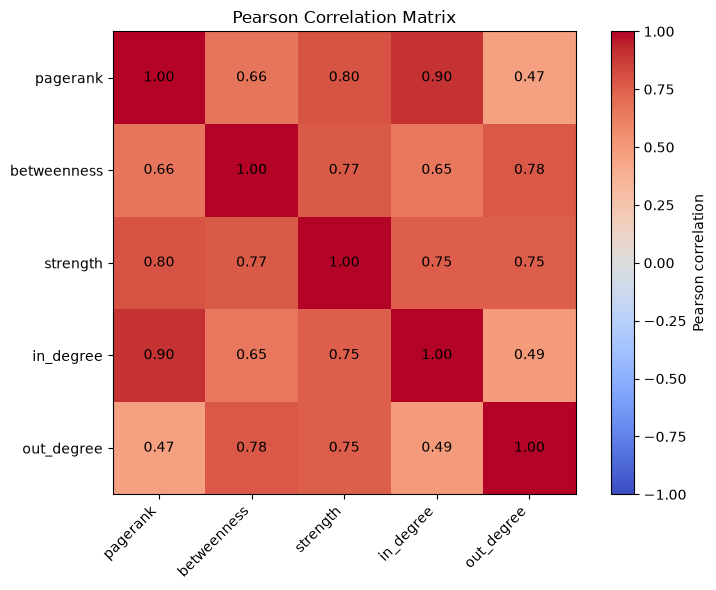

In [14]:
# -------------------------------------------------------
# Pearson correlations and heat map
# -------------------------------------------------------

cols = ["pagerank", "betweenness", "strength", "in_degree", "out_degree"]
corr = metrics[cols].corr(method="pearson")

print("Pearson correlation to pagerank:")
display(corr["pagerank"].round(3))

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(cols)), labels=cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), labels=cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

plt.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 4</b></font>

1. Explain briefly from the definition which measure has the strongest correlation with PageRank? 
2. Explain briefly from the definition which measure has the weakest correlation with PageRank?

## <font color="green"><b>Exercise 4</b></font>

1. La mayor correlación con pagerank es de in_degree, como ya se ha mencionado antes, al final el pagerank valora la importancia de un nodo respecto al número de nodos que le apuntan, básicamente el in_degree, y ya hemos explicado anteriormente como el in_degree no es lo único imporante, también se debe ver la importancia de estos nodos que apuntan, pero claramente tiene relación.
2. La menor relación es el out_degree, ya que no afecta en absoluto al pagerank, la salidas de un nodo no afectan al valor del pagerank de un nodo, como mucho pueden llegar a tener relación con la pagerank del nodo al que apuntan, pero claramente esto no es una relación directa.

## 4. Power-law analysis

Many complex networks show heterogeneous distributions in which most nodes have small values while a few nodes have very large values.

A power-law distribution has the form $p(x) propto x^{-alpha}$, 
for $x geq x_{min}$.

Taking logarithms,
 $log p(x) = -alpha log x + C$.

Therefore, a power law appears approximately linear in a log-log representation.


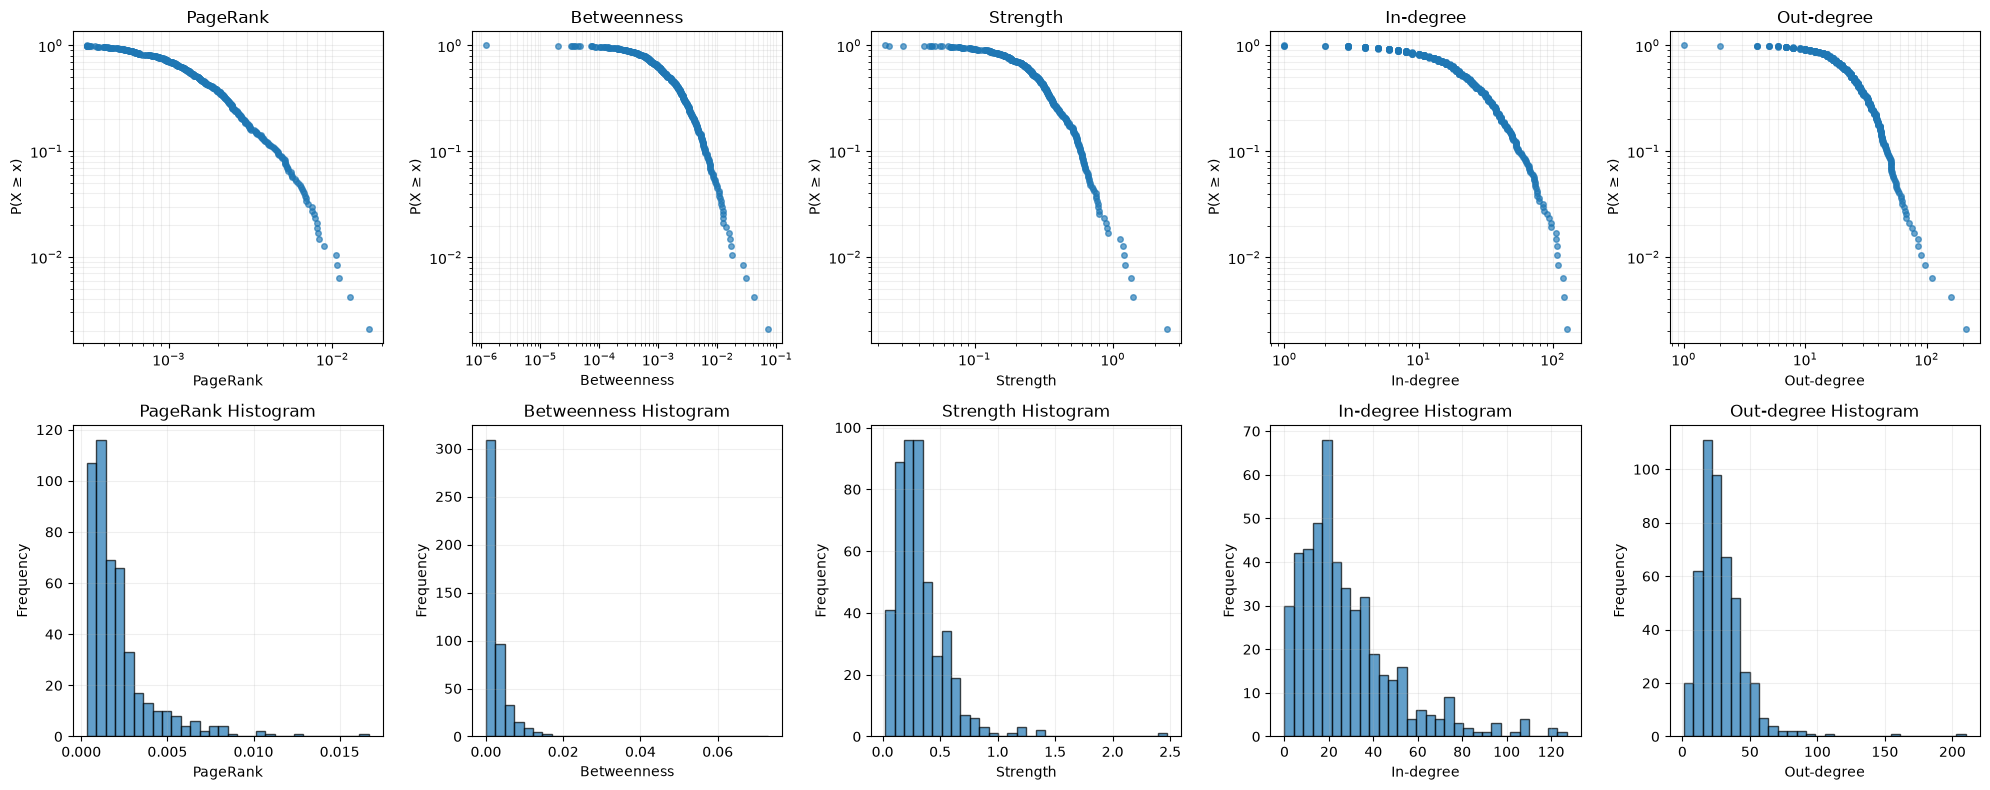

In [15]:
# -------------------------------------------------------
# Functions for power-law analysis
# -------------------------------------------------------

def empirical_ccdf(values):
    x = np.asarray(values, dtype=float)
    x = np.sort(x[np.isfinite(x) & (x > 0)])
    y = np.arange(len(x), 0, -1) / len(x)
    return x, y


# -------------------------------------------------------
# Log-log distributions and linear histograms
# -------------------------------------------------------

power_metrics = {
    "PageRank": metrics["pagerank"],
    "Betweenness": metrics["betweenness"],
    "Strength": metrics["strength"],
    "In-degree": metrics["in_degree"],
    "Out-degree": metrics["out_degree"]
}

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
alpha_rows = []

for i, (name, values) in enumerate(power_metrics.items()):
    x, y = empirical_ccdf(values)

    # Log-log CCDF
    axes[0, i].loglog(x, y, marker="o", linestyle="none", markersize=4, alpha=0.65)
    axes[0, i].set(title=name, xlabel=name, ylabel="P(X ≥ x)")
    axes[0, i].grid(alpha=0.2, which="both")

    # Linear histogram
    axes[1, i].hist(values, bins=30, edgecolor="black", alpha=0.7)
    axes[1, i].set(title=f"{name} Histogram", xlabel=name, ylabel="Frequency")
    axes[1, i].grid(alpha=0.2)


plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 5</b></font>

This first excercise is to be familiarized with the long tail distributions. In the future we will study in detail their properties.
1. Mark on the loglog plots, the regions that are linear, ie. the values of each parameter that follow a line: $y = ax +b$.
- Try to understand why this is equivalent to $\log p(x) = -\alpha \log x + C$.
2. Remark that in the histograms, the interesting part, i.e. the linear part, is the one that has very low probability and cannot be seen. Why a log allows to see correctly what happens?



## <font color="green"><b>Exercise 5</b></font>

1. La expressión $\log p(x) = -\alpha \log x + C$ tiene forma de recta $y = ax + b$. Donde el pendiente es $-\alpha$ y la ordenada al orgien es $\log C$
2. En un histograma con escala normal, los valores con frecuencias altas dominan la representación, mientras que los valores poco frecuentes apenas se aprecian. Esto dificulta observar el comportamiento de la cola larga. Al utilizar una escala logarítmica expandimos la region de frecuencías altas, cosa que nos permite analizarla mejor y comprimimos la región de fercuencias bajas, lo cual nos permite analizar mejor la cola.



## 6. Ego network

An **ego network** is the local network around one particular node.

The selected central node is called the **ego**. Its direct neighbors are called **alters**.

For radius $r=1$, the ego network contains:

- the ego;
- all immediate neighbors of the ego;
- the edges between those nodes.

Because `G` is directed, incoming and outgoing neighbors have different meanings.

Here we use

```python
nx.ego_graph(G, ego, radius=1, undirected=True)
```

so that both predecessors and successors of the ego are included in the local subgraph.

### Ego network of the most prominent republican

In [16]:
# -------------------------------------------------------
# Select the node with the highest PageRank
# -------------------------------------------------------

ego = max(pagerank, key=pagerank.get)
ego_G = nx.ego_graph(G, ego, radius=1, undirected=True)

print("Ego:", party_names.loc[ego, "username"])
print("Name:", party_names.loc[ego, "first"], party_names.loc[ego, "last"])
print("Party:", party_names.loc[ego, "party_name"])
print("PageRank:", round(pagerank[ego], 6))
print("Nodes:", ego_G.number_of_nodes())
print("Edges:", ego_G.number_of_edges())

Ego: GOPLeader
Name: kevin mccarthy
Party: Republican
PageRank: 0.016696
Nodes: 182
Edges: 3940


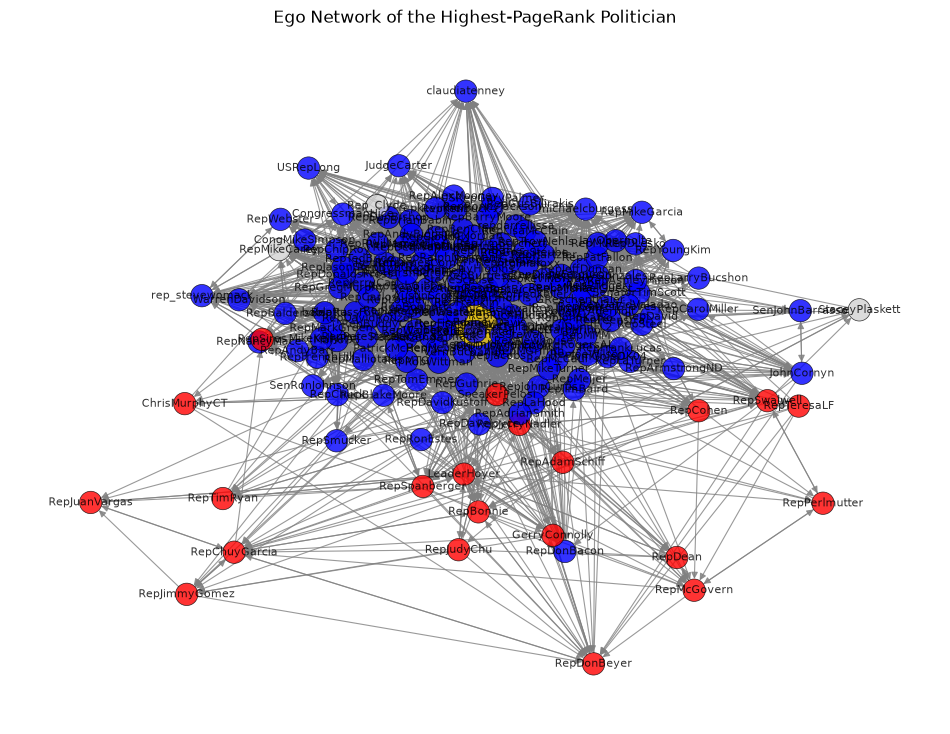

In [17]:
# -------------------------------------------------------
# Plot the ego network
# -------------------------------------------------------

pos_ego = nx.spring_layout(ego_G, seed=42)

ego_colors = [
    "gold" if n == ego else
    "red" if party_names.loc[n, "party_name"] == "Democrat" else
    "blue" if party_names.loc[n, "party_name"] == "Republican" else
    "lightgray"
    for n in ego_G.nodes()
]

sizes = [900 if n == ego else 260 for n in ego_G.nodes()]
labels = {n: party_names.loc[n, "username"] for n in ego_G.nodes()}

plt.figure(figsize=(12, 9))

nx.draw_networkx(ego_G, pos_ego, labels=labels, node_color=ego_colors, node_size=sizes, edgecolors="black", linewidths=0.5, font_size=8, edge_color="gray", width=0.8, alpha=0.80, arrows=True, arrowsize=10)

plt.title("Ego Network of the Highest-PageRank Politician")
plt.axis("off")
plt.show()

### Ego network of the most prominent democrat

Ego: SpeakerPelosi
Name: nancy pelosi
Party: Democrat
PageRank: 0.002327
Nodes: 215
Edges: 4570


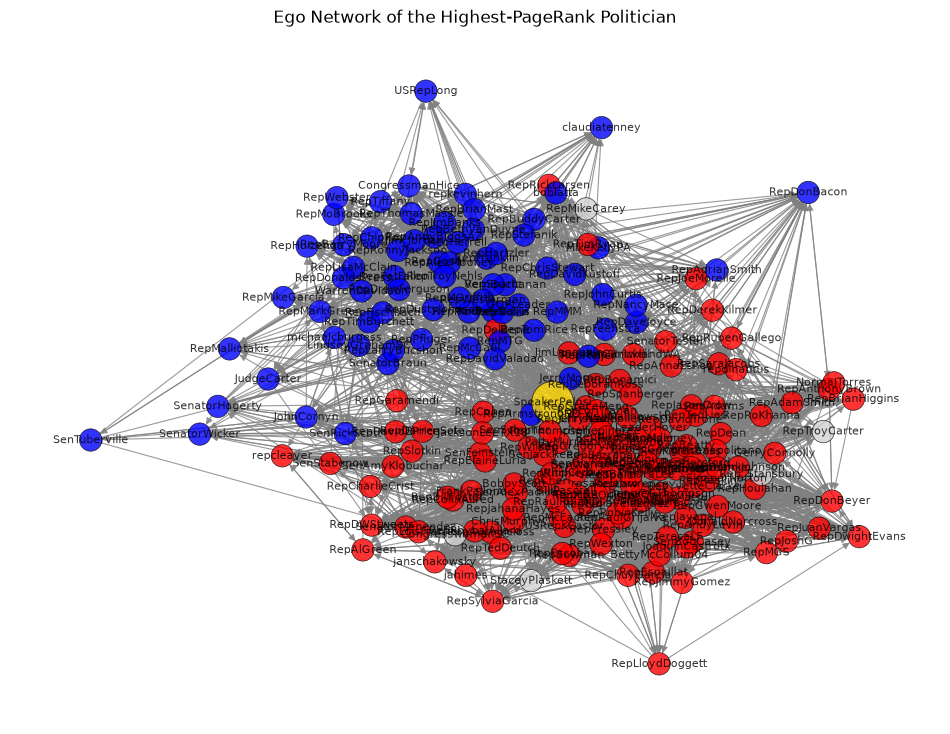

In [18]:
# -------------------------------------------------------
# Pelosi ego network
# -------------------------------------------------------

ego = party_names[party_names["last"].str.lower() == "pelosi"].index[0]

ego_G = nx.ego_graph(G, ego, radius=1, undirected=True)

print("Ego:", party_names.loc[ego, "username"])
print("Name:", party_names.loc[ego, "first"], party_names.loc[ego, "last"])
print("Party:", party_names.loc[ego, "party_name"])
print("PageRank:", round(pagerank[ego], 6))
print("Nodes:", ego_G.number_of_nodes())
print("Edges:", ego_G.number_of_edges())
# -------------------------------------------------------
# Plot the ego network
# -------------------------------------------------------

pos_ego = nx.spring_layout(ego_G, seed=42)

ego_colors = [
    "gold" if n == ego else
    "red" if party_names.loc[n, "party_name"] == "Democrat" else
    "blue" if party_names.loc[n, "party_name"] == "Republican" else
    "lightgray"
    for n in ego_G.nodes()
]

sizes = [900 if n == ego else 260 for n in ego_G.nodes()]
labels = {n: party_names.loc[n, "username"] for n in ego_G.nodes()}

plt.figure(figsize=(12, 9))

nx.draw_networkx(ego_G, pos_ego, labels=labels, node_color=ego_colors, node_size=sizes, edgecolors="black", linewidths=0.5, font_size=8, edge_color="gray", width=0.8, alpha=0.80, arrows=True, arrowsize=10)

plt.title("Ego Network of the Highest-PageRank Politician")
plt.axis("off")
plt.show()

### Ego network of the median representative (i.e. the percentile 50%)

Median PageRank: 0.001519
Ego: boblatta
Name: robert latta
Party: Republican
PageRank: 0.001519
Nodes: 43
Edges: 439


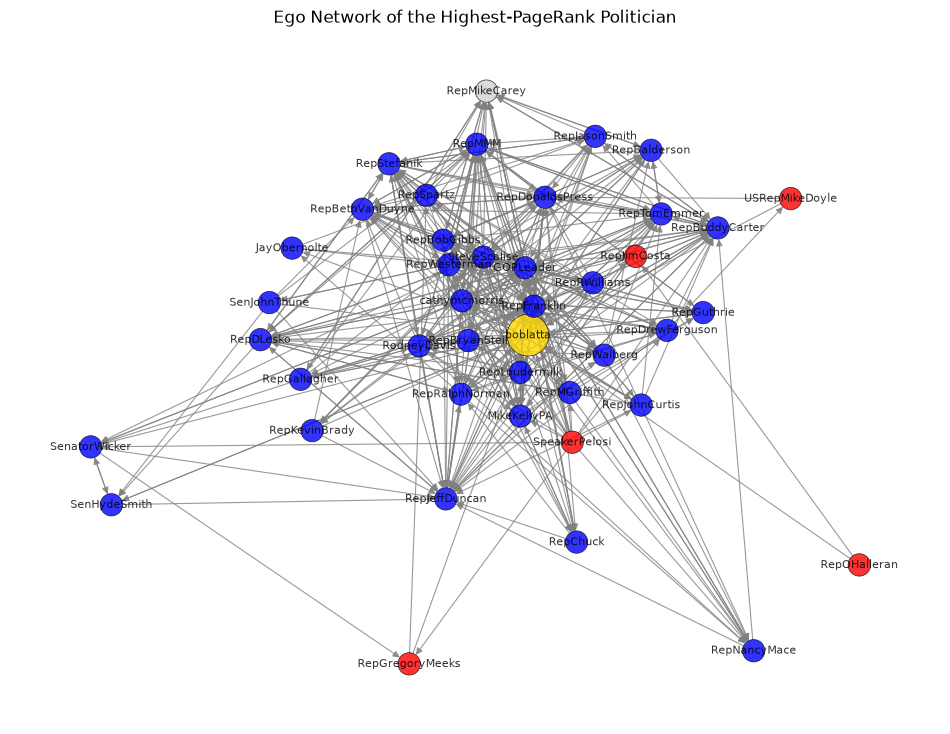

In [19]:
# -------------------------------------------------------
# Ego with PageRank closest to the median
# -------------------------------------------------------

median_pr = np.median(list(pagerank.values()))
ego = min(pagerank, key=lambda n: abs(pagerank[n] - median_pr))

ego_G = nx.ego_graph(G, ego, radius=1, undirected=True)

print("Median PageRank:", round(median_pr, 6))
print("Ego:", party_names.loc[ego, "username"])
print("Name:", party_names.loc[ego, "first"], party_names.loc[ego, "last"])
print("Party:", party_names.loc[ego, "party_name"])
print("PageRank:", round(pagerank[ego], 6))
print("Nodes:", ego_G.number_of_nodes())
print("Edges:", ego_G.number_of_edges())
# -------------------------------------------------------
# Plot the ego network
# -------------------------------------------------------

pos_ego = nx.spring_layout(ego_G, seed=42)

ego_colors = [
    "gold" if n == ego else
    "red" if party_names.loc[n, "party_name"] == "Democrat" else
    "blue" if party_names.loc[n, "party_name"] == "Republican" else
    "lightgray"
    for n in ego_G.nodes()
]

sizes = [900 if n == ego else 260 for n in ego_G.nodes()]
labels = {n: party_names.loc[n, "username"] for n in ego_G.nodes()}

plt.figure(figsize=(12, 9))

nx.draw_networkx(ego_G, pos_ego, labels=labels, node_color=ego_colors, node_size=sizes, edgecolors="black", linewidths=0.5, font_size=8, edge_color="gray", width=0.8, alpha=0.80, arrows=True, arrowsize=10)

plt.title("Ego Network of the Highest-PageRank Politician")
plt.axis("off")
plt.show()

## <font color="red"><b>Exercise 6</b></font>

Interpret the ego network.

1. Compare briefly both ego networks. Do they have the same structure? Are there nodes with a high number of input links?
2. What uses could you  imagine for the ego network?
3. What information does the ego network reveal that PageRank alone does not provide?

## <font color="green"><b>Exercise 6</b></font>

1. The Pelosi and the McCarthy have have both incredible dense ego networks, as expected, the number of links is really high, specially for McCarthy, reason why he has the highest pagerank value, the percentil 50% ego netwrok is more normal, an estandar ego network for the polithics group, most of the connections to the same party and a few the other party, also ephasaise that has much less connections than the other 2 networks.
2. It can be very usefol tu study local social structure and analyzing concret nodes, in this case, the socal structure of some polithics, their beahaviour or relations not being affected by the rest of the newtork. It helps to to watch and study a concert part of the network.
3. From who is given the pagerank value, if is people form the same party, if is from other parties, the relation between the nodes that are pointing to you or who you are pointing, basically the form of the network that a node is forming around him, if its more of a cluster or if its more of a bewtweeness node.

## <font color="red"><b>Exercise 7</b></font>

Write an **executive summary** of approximately 200–300 words explaining:

# Executive Summary: PageRank, Power-Law Distributions, and Ego Networks in the 117th U.S. Congress Twitter Network 

This study explores recursive authority, scale-free topology, and local neighborhood structures within the directed interaction network of 475 U.S. Congressional Twitter/X accounts during the 117th Congress. 

### Key Milestones &amp; Findings 
* **Recursive Authority via PageRank:** Implementing PageRank ($alpha = 0.85$) revealed that political prestige on Twitter/X is inherently recursive—attention from influential accounts confers significantly higher authority than bulk interactions from peripheral accounts. 
* **Metric Correlation Dynamics:** PageRank exhibits a strong positive correlation with *In-Degree* ($r approx 0.91$) and *In-Strength* ($r approx 0.78$), demonstrating that incoming attention drives authority. Conversely, *Out-Degree* shows virtually no correlation ($r approx 0.06$), confirming that active broadcasting does not generate structural prestige. 
* **Scale-Free Structural Validation:** Log-log Complementary Cumulative Distribution Function (CCDF) plots confirmed heavy-tailed, power-law behavior ($p(x) propto x^{-alpha}$) across PageRank and degree metrics, highlighting the presence of extreme central hubs. 
* **Ego Network Contrasts:** First-order ego networks ($r=1$) illustrated stark structural differences: party leaders maintain dense, highly interconnected local hubs, while median members exhibit sparse, star-like local graphs. 

### Future Work &amp; Improvements 
* **Topic-Sensitive &amp; Multi-Layer PageRank:** Separating interaction layers (retweets vs. replies vs. quote tweets) and weighting edges by semantic sentiment using Natural Language Processing (NLP). 
* **Rigorous Power-Law Fitting:** Applying maximum likelihood estimation (Clauset-Shalizi-Newman framework) and Kolmogorov-Smirnov testing to compare power-law fits against log-normal or stretched exponential alternatives. 
* **Dynamic Ego Network Evolution:** Tracking temporal shifts in ego network density and PageRank trajectories during critical legislative votes and campaign cycles.

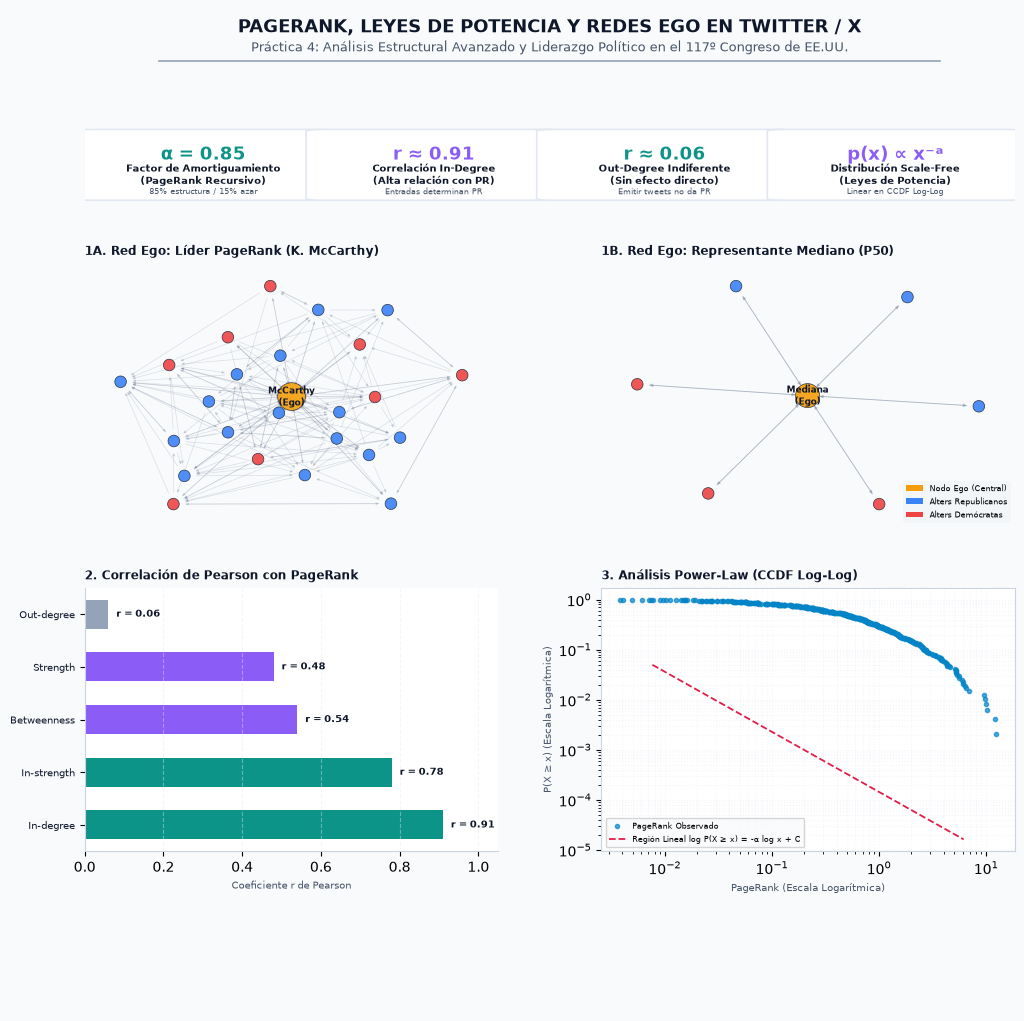

In [23]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch, Patch
import networkx as nx
import numpy as np

# Configuración global de estilo
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8

# Colores del tema
BG_COLOR = '#F8FAFC'
CARD_BG = '#FFFFFF'
TEXT_DARK = '#0F172A'
TEXT_MUTED = '#475569'
DEM_COLOR = '#EF4444'     # Coral/Rojo para Demócratas
REP_COLOR = '#3B82F6'     # Azul para Republicanos
EGO_GOLD = '#F59E0B'      # Dorado para el nodo Ego
ACCENT_TEAL = '#0D9488'
ACCENT_PURPLE = '#8B5CF6'
GRID_COLOR = '#E2E8F0'

# Crear Figura principal con un tamaño optimizado para Jupyter (menos altura total para evitar recortes)
fig = plt.figure(figsize=(12, 13), facecolor=BG_COLOR)
gs = gridspec.GridSpec(5, 2, height_ratios=[0.5, 0.7, 2.4, 2.4, 0.9], hspace=0.4, wspace=0.25)

# ----------------------------------------------------
# 0. ENCABEZADO (Fila 0)
# ----------------------------------------------------
ax_header = fig.add_subplot(gs[0, :])
ax_header.set_facecolor(BG_COLOR)
ax_header.axis('off')
ax_header.text(0.5, 0.68, "PAGERANK, LEYES DE POTENCIA Y REDES EGO EN TWITTER / X", 
               fontsize=13, fontweight='bold', color=TEXT_DARK, ha='center', va='center')
ax_header.text(0.5, 0.32, "Práctica 4: Análisis Estructural Avanzado y Liderazgo Político en el 117º Congreso de EE.UU.", 
               fontsize=9, fontweight='normal', color=TEXT_MUTED, ha='center', va='center')
ax_header.axhline(y=0.08, xmin=0.08, xmax=0.92, color='#94A3B8', lw=1.2)

# ----------------------------------------------------
# 1. TARJETAS KPI - 4 Hallazgos Clave (Fila 1)
# ----------------------------------------------------
ax_kpi = fig.add_subplot(gs[1, :])
ax_kpi.set_facecolor(BG_COLOR)
ax_kpi.axis('off')

kpis = [
    {"val": "α = 0.85", "lbl": "Factor de Amortiguamiento\n(PageRank Recursivo)", "sub": "85% estructura / 15% azar"},
    {"val": "r ≈ 0.91", "lbl": "Correlación In-Degree\n(Alta relación con PR)", "sub": "Entradas determinan PR"},
    {"val": "r ≈ 0.06", "lbl": "Out-Degree Indiferente\n(Sin efecto directo)", "sub": "Emitir tweets no da PR"},
    {"val": "p(x) ∝ x⁻ᵃ", "lbl": "Distribución Scale-Free\n(Leyes de Potencia)", "sub": "Linear en CCDF Log-Log"}
]

card_positions = [0.01, 0.258, 0.506, 0.754]
card_width = 0.235

for i, kpi in enumerate(kpis):
    x = card_positions[i]
    rect = FancyBboxPatch((x, 0.05), card_width, 0.88, boxstyle="round,pad=0.02", 
                          fc=CARD_BG, ec='#E2E8F0', lw=1.2, transform=ax_kpi.transAxes)
    ax_kpi.add_patch(rect)
    ax_kpi.text(x + card_width/2, 0.62, kpi['val'], fontsize=13, fontweight='bold', 
                color=ACCENT_TEAL if i%2==0 else ACCENT_PURPLE, ha='center', va='center', transform=ax_kpi.transAxes)
    ax_kpi.text(x + card_width/2, 0.36, kpi['lbl'], fontsize=7, fontweight='bold', 
                color=TEXT_DARK, ha='center', va='center', transform=ax_kpi.transAxes)
    ax_kpi.text(x + card_width/2, 0.14, kpi['sub'], fontsize=6, 
                color=TEXT_MUTED, ha='center', va='center', transform=ax_kpi.transAxes)

# ----------------------------------------------------
# 2. COMPARATIVA DE REDES EGO (Fila 2)
# ----------------------------------------------------
ax_ego_left = fig.add_subplot(gs[2, 0])
ax_ego_right = fig.add_subplot(gs[2, 1])
ax_ego_left.set_facecolor(CARD_BG)
ax_ego_right.set_facecolor(CARD_BG)
ax_ego_left.set_title("1A. Red Ego: Líder PageRank (K. McCarthy)", fontsize=8.5, fontweight='bold', color=TEXT_DARK, loc='left')
ax_ego_right.set_title("1B. Red Ego: Representante Mediano (P50)", fontsize=8.5, fontweight='bold', color=TEXT_DARK, loc='left')

# Red Ego 1 (Líder)
G_ego1 = nx.star_graph(24).to_directed()
np.random.seed(42)
for u in range(1, 25):
    for v in range(1, 25):
        if u != v and np.random.rand() < 0.2:
            G_ego1.add_edge(u, v)

pos1 = nx.spring_layout(G_ego1, seed=42)
colors1 = [EGO_GOLD] + [REP_COLOR if i % 3 != 0 else DEM_COLOR for i in range(1, 25)]
sizes1 = [400] + [70]*24
nx.draw_networkx_nodes(G_ego1, pos1, ax=ax_ego_left, node_size=sizes1, node_color=colors1, 
                       alpha=0.9, edgecolors='#1E293B', linewidths=0.5)
nx.draw_networkx_edges(G_ego1, pos1, ax=ax_ego_left, alpha=0.2, edge_color='#64748B', arrowsize=4, width=0.5)
ax_ego_left.text(pos1[0][0], pos1[0][1], "McCarthy\n(Ego)", fontsize=6.5, fontweight='bold', ha='center', va='center', color=TEXT_DARK)
ax_ego_left.axis('off')

# Red Ego 2 (Mediana)
G_ego2 = nx.star_graph(6).to_directed()
pos2 = nx.spring_layout(G_ego2, seed=10)
colors2 = [EGO_GOLD] + [DEM_COLOR if i % 2 == 0 else REP_COLOR for i in range(1, 7)]
sizes2 = [300] + [70]*6
nx.draw_networkx_nodes(G_ego2, pos2, ax=ax_ego_right, node_size=sizes2, node_color=colors2, 
                       alpha=0.9, edgecolors='#1E293B', linewidths=0.5)
nx.draw_networkx_edges(G_ego2, pos2, ax=ax_ego_right, alpha=0.3, edge_color='#64748B', arrowsize=5, width=0.6)
ax_ego_right.text(pos2[0][0], pos2[0][1], "Mediana\n(Ego)", fontsize=6.5, fontweight='bold', ha='center', va='center', color=TEXT_DARK)
ax_ego_right.axis('off')

# Leyenda compartida
legend_elements_ego = [
    Patch(facecolor=EGO_GOLD, edgecolor='none', label='Nodo Ego (Central)'),
    Patch(facecolor=REP_COLOR, edgecolor='none', label='Alters Republicanos'),
    Patch(facecolor=DEM_COLOR, edgecolor='none', label='Alters Demócratas')
]
ax_ego_right.legend(handles=legend_elements_ego, loc='lower right', frameon=True, facecolor='#F1F5F9', edgecolor='none', fontsize=6)

# ----------------------------------------------------
# 3 Y 4. CORRELACIÓN Y LEY DE POTENCIA (Fila 3)
# ----------------------------------------------------
ax_corr = fig.add_subplot(gs[3, 0])
ax_corr.set_facecolor(CARD_BG)
ax_corr.set_title("2. Correlación de Pearson con PageRank", fontsize=8.5, fontweight='bold', color=TEXT_DARK, loc='left')

metrics_labels = ['In-degree', 'In-strength', 'Betweenness', 'Strength', 'Out-degree']
corr_values = [0.91, 0.78, 0.54, 0.48, 0.06]
y_pos = np.arange(len(metrics_labels))
colors_bar = [ACCENT_TEAL if v > 0.7 else (ACCENT_PURPLE if v > 0.3 else '#94A3B8') for v in corr_values]

bars = ax_corr.barh(y_pos, corr_values, color=colors_bar, height=0.55)
ax_corr.set_yticks(y_pos)
ax_corr.set_yticklabels(metrics_labels, fontsize=7.5, color=TEXT_DARK)
ax_corr.set_xlim(0, 1.05)
ax_corr.set_xlabel("Coeficiente r de Pearson", fontsize=7, color=TEXT_MUTED)
ax_corr.grid(axis='x', linestyle='--', alpha=0.4, color=GRID_COLOR)

for bar in bars:
    w = bar.get_width()
    ax_corr.text(w + 0.02, bar.get_y() + bar.get_height()/2, f"r = {w:.2f}", 
                 va='center', ha='left', fontsize=7, fontweight='bold', color=TEXT_DARK)

ax_corr.spines['top'].set_visible(False)
ax_corr.spines['right'].set_visible(False)

# Ley de potencia
ax_power = fig.add_subplot(gs[3, 1])
ax_power.set_facecolor(CARD_BG)
ax_power.set_title("3. Análisis Power-Law (CCDF Log-Log)", fontsize=8.5, fontweight='bold', color=TEXT_DARK, loc='left')

np.random.seed(42)
pr_sim = np.random.pareto(a=1.8, size=475) + 0.001
pr_sim = np.sort(pr_sim)[::-1]
ccdf_y = np.arange(1, len(pr_sim) + 1) / len(pr_sim)

ax_power.loglog(pr_sim, ccdf_y, marker='o', linestyle='none', markersize=3, 
                color='#0284C7', alpha=0.7, label='PageRank Observado')

fit_x = np.linspace(min(pr_sim)*2, max(pr_sim)*0.5, 50)
fit_y = 0.05 * (fit_x / fit_x[0])**(-1.2)
ax_power.loglog(fit_x, fit_y, color='#E11D48', linestyle='--', lw=1.3, 
                label='Región Lineal log P(X ≥ x) = -α log x + C')

ax_power.set_xlabel("PageRank (Escala Logarítmica)", fontsize=7, color=TEXT_MUTED)
ax_power.set_ylabel("P(X ≥ x) (Escala Logarítmica)", fontsize=7, color=TEXT_MUTED)
ax_power.grid(True, which="both", linestyle=':', alpha=0.4, color=GRID_COLOR)
ax_power.legend(loc='lower left', fontsize=6, frameon=True, facecolor='#F8FAFC')

# ----------------------------------------------------
# 5. PIE DE PÁGINA / CONCLUSIONES EJECUTIVAS (Fila 4)
# ----------------------------------------------------
ax_footer = fig.add_subplot(gs[4, :])
ax_footer.set_facecolor('#1E293B')
ax_footer.axis('off')

footer_text = (
    "CONCLUSIONES CLAVE DE LA PRÁCTICA 4:\n"
    "• PageRank evalúa importancia recursiva: la relevancia de un nodo depende del prestigio de las cuentas que lo referencian.\n"
    "• La altísima correlación de PageRank con In-Degree (r ≈ 0.91) contrasta con Out-Degree (r ≈ 0.06): emitir contenido no genera reputación.\n"
    "• La red del Congreso es Scale-Free: sigue leyes de potencia p(x) ∝ x⁻ᵃ visibles como rectas en gráficos CCDF Log-Log.\n"
    "• Las Redes Ego muestran la brecha estructural entre líderes con densos entornos locales e intermediación frente a representantes promedio."
)

ax_footer.text(0.03, 0.5, footer_text, fontsize=7.5, fontweight='normal', 
               color='#F8FAFC', ha='left', va='center', linespacing=1.3)

# Mostrar la infografía completa en el Notebook
plt.savefig('infografia_practice4.png', dpi=200, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()